<img src="https://www.pucsp.br/sites/default/files/download/brasao-PUCSP-assinatura-principal-RGB.png" style="float:right;" width="150px">

# Ciências da Computação [》](https://www.pucsp.br/graduacao/ciencia-da-computacao)

## Inteligência Artificial

IA ML (Machine Learning, Aprendizagem de Máquina)

**Objetivo desta aula e LAB explorar os modelos de Árvore de Decisão (Decision Tree) com Scikit-Learn em Python, sobre os dados do Titanic (clássico de IA EDUCATION) e outros dados do Vega Dataset**

Inteligência Artificial - ML com Scikit-learn



**Equipe:**

Luís Augusto Coelho de Souza RA00331675  
Guilherme Schnekenberg Teixeira RA00336189

# **Chosen dataset - Movies**

### **Target feature: Success**  
  
We want to predict, before a movie is released, whether it will be a commercial success. A movie is labeled a success if its worldwide gross exceeds its production budget (Worldwide_Gross > Production_Budget). Otherwise it is labeled a flop. This is a binary classification problem.

We chose production budget, running time, MPAA rating, genre, source material, creative type, distributor, and release year and month. These reflect the decisions made during development and planning, and they relate to success in plausible ways: bigger budgets raise the bar for profitability, genres and source types (original, sequel, adaptation) attract different audience sizes, ratings limit the audience, and release timing affects competition and seasonal demand.

In [91]:
import pandas as pd
import numpy as np

import missingno as msno
from vega_datasets import data
import matplotlib.pyplot as plt
import seaborn as sns

In [92]:
movie_df = data.movies()

movie_df.columns

Index(['Title', 'US_Gross', 'Worldwide_Gross', 'US_DVD_Sales',
       'Production_Budget', 'Release_Date', 'MPAA_Rating', 'Running_Time_min',
       'Distributor', 'Source', 'Major_Genre', 'Creative_Type', 'Director',
       'Rotten_Tomatoes_Rating', 'IMDB_Rating', 'IMDB_Votes'],
      dtype='object')

In [93]:
## Kepping Title for visualization later
feature_cols = ['Title', 'Production_Budget', 'Worldwide_Gross', 'Running_Time_min', 'MPAA_Rating',
                'Major_Genre', 'Source', 'Creative_Type', 'Distributor', 'Release_Date']

movie_df = movie_df[feature_cols]

# Exploratory Data Analysis

In [94]:
movie_df.shape

(3201, 10)

In [95]:
movie_df

,Title,Production_Budget,Worldwide_Gross,Running_Time_min,MPAA_Rating,Major_Genre,Source,Creative_Type,Distributor,Release_Date
0,The Land Girls,8000000.0,146083.0,NaN,R,None,None,None,Gramercy,Jun 12 1998
1,"First Love, Last Rites",300000.0,10876.0,NaN,R,Drama,None,None,Strand,Aug 07 1998
2,I Married a Strange Person,250000.0,203134.0,NaN,None,Comedy,None,None,Lionsgate,Aug 28 1998
3,Let's Talk About Sex,300000.0,373615.0,NaN,None,Comedy,None,None,Fine Line,Sep 11 1998
4,Slam,1000000.0,1087521.0,NaN,R,Drama,Original Screenplay,Contemporary Fiction,Trimark,Oct 09 1998
...,...,...,...,...,...,...,...,...,...,...
3196,Zack and Miri Make a Porno,24000000.0,36851125.0,101.0,R,Comedy,Original Screenplay,Contemporary Fiction,Weinstein Co.,Oct 31 2008
3197,Zodiac,85000000.0,83080084.0,157.0,R,Thriller/Suspense,Based on Book/Short Story,Dramatization,Paramount Pictures,Mar 02 2007
3198,Zoom,35000000.0,12506188.0,NaN,PG,Adventure,Based on Comic/Graphic Novel,Super Hero,Sony Pictures,Aug 11 2006
3199,The Legend of Zorro,80000000.0,141475336.0,129.0,PG,Adventure,Remake,Historical Fiction,Sony Pictures,Oct 28 2005


## Missingness analysis


In [96]:
movie_df.isnull().sum().sort_values(ascending=False)

,0
Running_Time_min,1992
MPAA_Rating,605
Creative_Type,446
Source,365
Major_Genre,275
Distributor,232
Worldwide_Gross,7
Title,1
Production_Budget,1
Release_Date,0


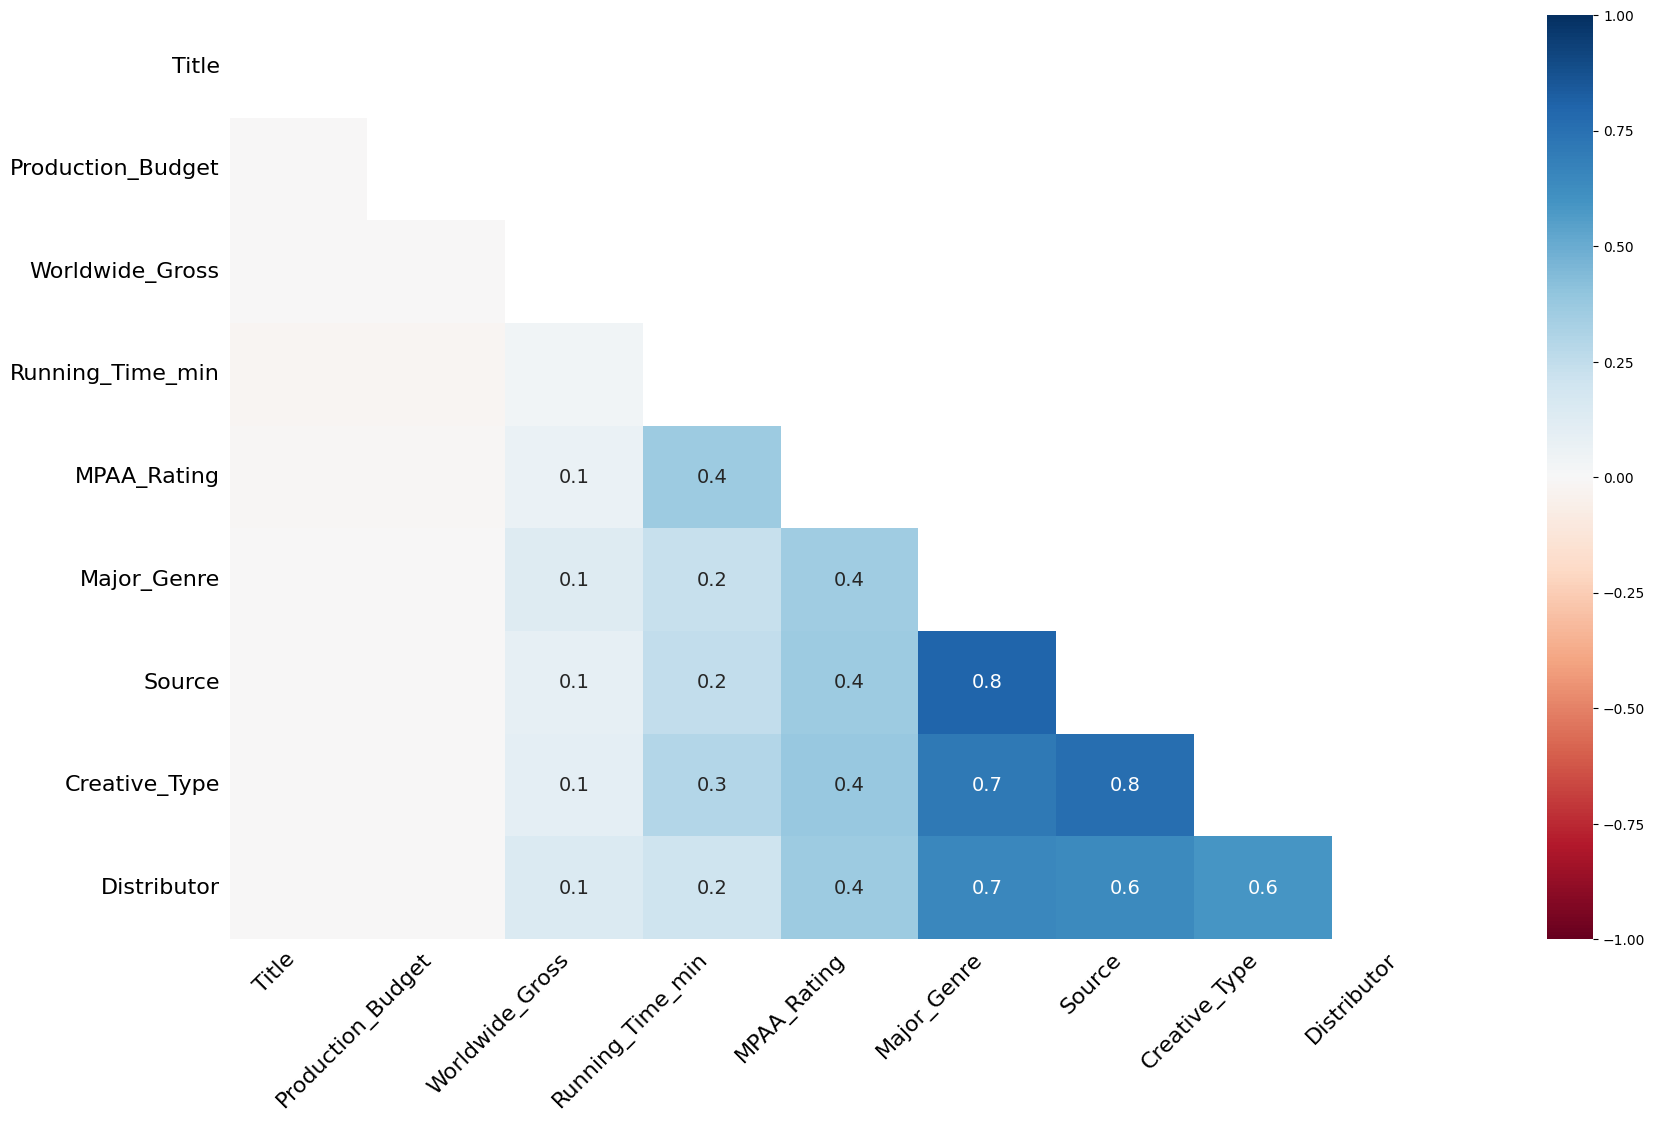

In [97]:
msno.heatmap(movie_df)
plt.show()

After the missingness analysis, we realize that there are strong relations in the missingness of the following features:
- Source, Creative_Type, Distributor
- MPAA_Rating - Major_Genre, Source, Creative_Type and Distributor
- MPAA_Rating - Running_Time_min

In [98]:
def display_missing_values_cor(df, *col_names):
    """
    Bar chart of missing-value patterns across N columns,
    ordered by number of columns missing (0, 1, ..., all).
    """
    names = list(col_names)
    total = len(df)
    flags = df[names].isna()

    def label_for(row):
        missing = [n for n, f in zip(names, row) if f]
        if not missing:
            return "None missing", 0
        if len(missing) == len(names):
            return "All missing", len(names)
        return " & ".join(missing) + " only", len(missing)

    pairs = [label_for(r) for r in flags.itertuples(index=False)]
    n_missing_lookup = dict(pairs)
    categories = pd.Series([p[0] for p in pairs]).value_counts()
    categories = categories.reindex(
        sorted(categories.index, key=lambda l: (n_missing_lookup[l], l))
    )

    # Sanity check: per-column totals must match df[col].isna().sum()
    for n in names:
        shown = sum(c for lbl, c in categories.items()
                    if n in lbl or lbl == "All missing")
        assert shown == df[n].isna().sum(), f"Label mismatch for {n}"

    palette = ["#4c72b0", "#dd8452", "#8172b2", "#937860", "#da8bc3"]
    color_map = {"None missing": "#55a868", "All missing": "#c44e52"}
    colors = [color_map.get(c, palette[n_missing_lookup[c] % len(palette)])
              for c in categories.index]

    fig, ax = plt.subplots(figsize=(8 + len(names), 5))
    bars = ax.bar(categories.index, categories.values, color=colors)
    for bar, count in zip(bars, categories.values):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(),
                f"{count:,}\n({count/total:.1%})", ha="center", va="bottom", fontsize=10)

    ax.set_ylabel("Number of movies")
    ax.set_title(f'Missingness pattern: {" vs. ".join(names)} (n={total:,})')
    ax.margins(y=0.15)
    plt.xticks(rotation=15, ha="right")
    plt.tight_layout()
    plt.savefig("missingness_" + "_".join(names) + ".png", dpi=150)
    plt.show()

Exploring Source, Creative_Type and Distributor

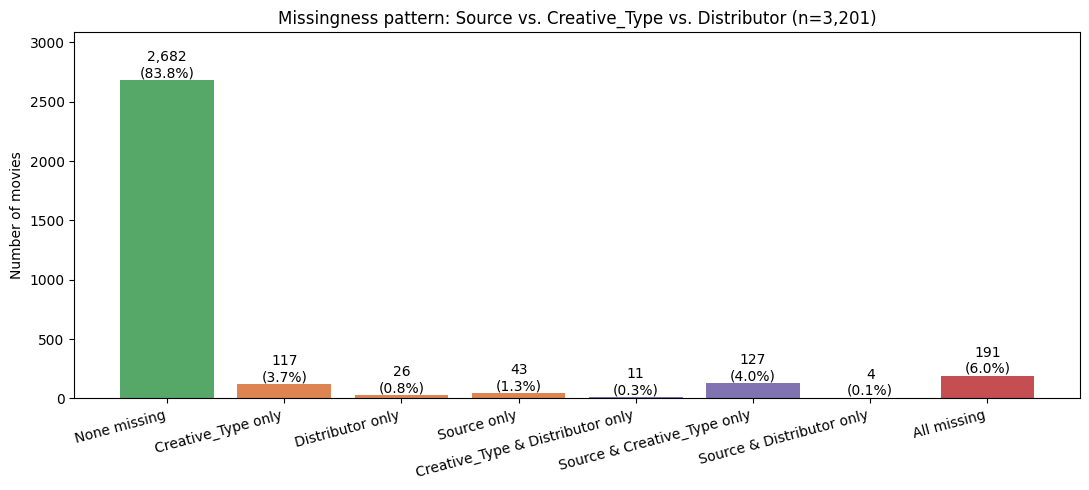

In [99]:
display_missing_values_cor(movie_df, 'Source', 'Creative_Type', 'Distributor')

Exploring MPAA_Rating with Source, Creative_Type, Distributor and Major_Genre

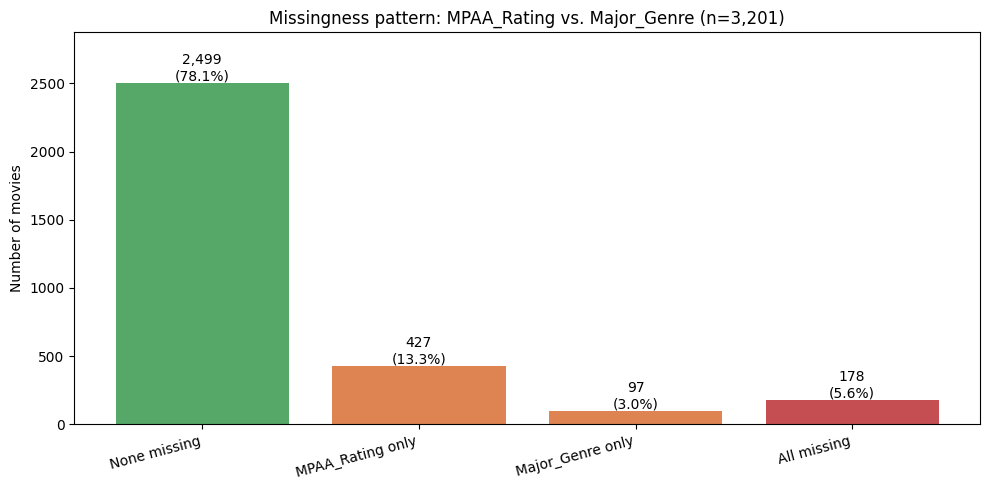

In [100]:
display_missing_values_cor(movie_df, 'MPAA_Rating', 'Major_Genre')

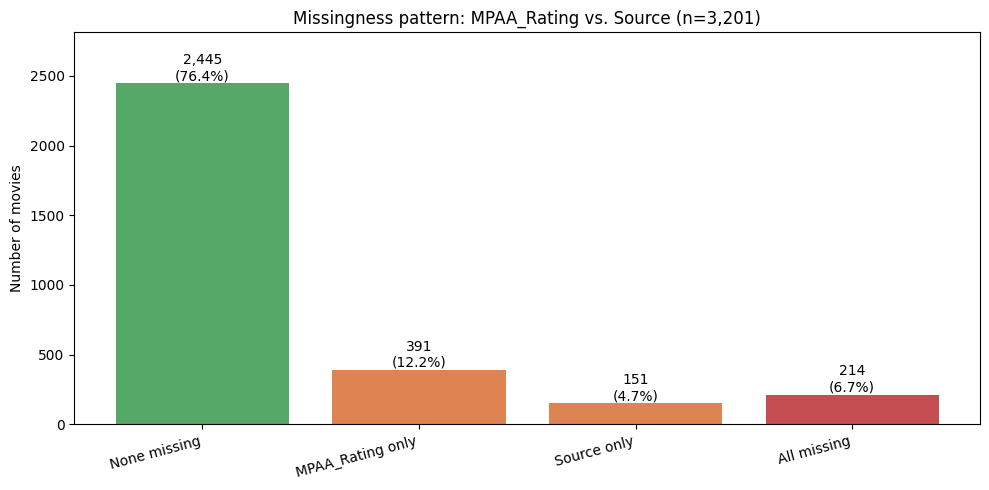

In [101]:
display_missing_values_cor(movie_df, 'MPAA_Rating', 'Source')

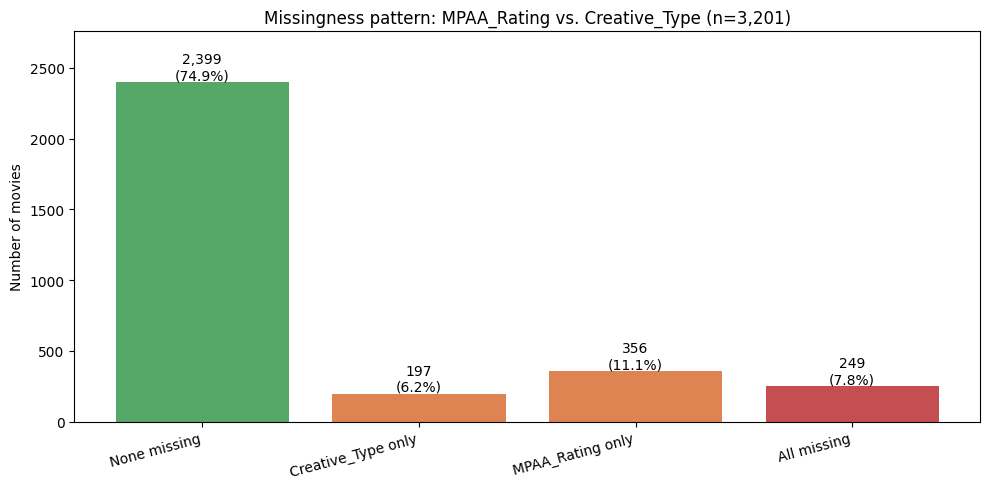

In [102]:
display_missing_values_cor(movie_df, 'MPAA_Rating', 'Creative_Type')

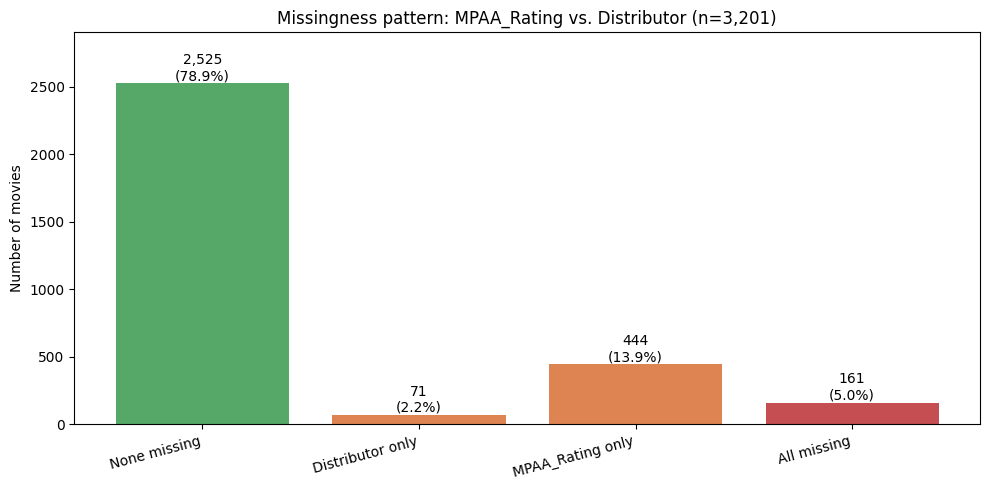

In [103]:
display_missing_values_cor(movie_df, 'MPAA_Rating', 'Distributor')

Exploring MPAA_Rating and Running_Time_min

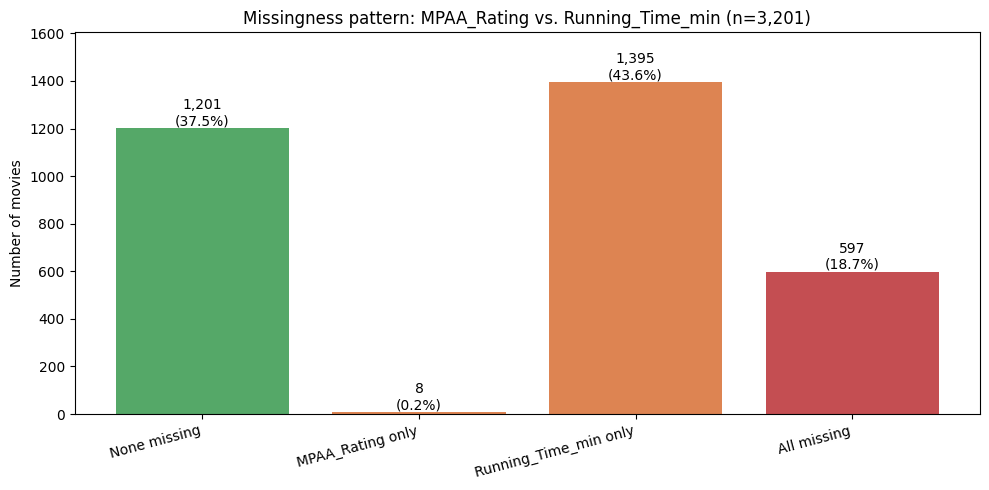

In [104]:
display_missing_values_cor(movie_df, 'MPAA_Rating', 'Running_Time_min')

### Conclusions

Percentages are conditional: "given A is missing, B is also missing", compared with each column's overall missing rate.

- **Metadata block:** Source, Creative_Type and Distributor overlap strongly but asymmetrically. When Distributor is missing, Source and Creative_Type are also missing in 84% and 87% of cases. Only 6.0% of all movies are missing all three.
- **MPAA_Rating:** when Source, Creative_Type or Distributor is missing, MPAA_Rating is also missing in 56-69% of cases (base rate 18.9%). The reverse link is weaker (27-41%).
- **Running_Time_min:** when MPAA_Rating is missing, Running_Time_min is also missing in 98.7% of cases (base rate 62.2%). In the other direction it is only 30%.

The gaps are structured rather than random, so we keep these rows, fill categorical gaps with "Unknown", and add missing indicators.

### Are movies with a missing MPAA rating different from the rest?

Since the MPAA_rating feature missingness is correlated with a lot of other features, it would be interesting to investigate this relationship:

- The first output compares the **median production budget** of the two groups. The median is used because budgets are heavily right-skewed.
- The second output summarizes **release year** for each group (count, mean, quartiles, min, max).

**Result:** movies without a rating are cheaper (median budget \$7M vs. \$24M) and older (median release year 1985 vs. 2003). The middle 50% of years barely overlap (1975-1991 vs. 1999-2006). A missing rating is therefore acting as a proxy for "old, low-budget movie", so any model that uses a missing-rating indicator will partly be picking up era and budget.

**Data issue:** the year summary shows max years of 2039 and 2046, this issue will be investigated later

In [105]:
movie_df["rating_missing"] = movie_df["MPAA_Rating"].isna()
print(movie_df.groupby("rating_missing")[["Production_Budget"]].median())
print(movie_df.assign(year=pd.to_datetime(movie_df["Release_Date"], errors="coerce").dt.year)
      .groupby("rating_missing")["year"].describe())

                Production_Budget
rating_missing                   
False                  24000000.0
True                    7000000.0
                 count         mean        std     min     25%     50%  \
rating_missing                                                           
False           2596.0  2001.901002   6.198811  1944.0  1999.0  2003.0   
True             605.0  1983.256198  17.516468  1928.0  1975.0  1985.0   

                   75%     max  
rating_missing                  
False           2006.0  2039.0  
True            1991.0  2046.0  


### Data Issue

Uppon investigation, there are movie release dates releasing century errors in the source data (e.g. *The Best Years of Our Lives* is dated 2046 instead of 1946). They inflate the means and standard deviations, but they barely affect the medians and quartiles that the conclusion relies on. The dates are corrected in the following cells, and this comparison should be rerun on the corrected years.

In [106]:
d = pd.to_datetime(movie_df["Release_Date"], format="%b %d %Y", errors="coerce")
movie_df["release_month"] = d.dt.month
movie_df["release_year"] = d.dt.year

In [107]:
# This date was manually defined after inspecting some examples from years prior to 2011, which came back to an accurate response.
CUTOFF = 2011

movie_df["century_fixed"] = movie_df["release_year"] > CUTOFF
movie_df["release_year_fixed"] = movie_df["release_year"].where(
    ~movie_df["century_fixed"], movie_df["release_year"] - 100
)

In [108]:
# Printing the adjusted columns
print(movie_df["century_fixed"].sum())
print(movie_df["release_year_fixed"].describe())
print(movie_df.loc[movie_df["century_fixed"],
                   ["Title", "release_year", "release_year_fixed"]]
      .sort_values("release_year_fixed"))
print(movie_df["release_year_fixed"].value_counts().sort_index().tail(8))

22
count    3201.000000
mean     1997.689784
std        12.754276
min      1915.000000
25%      1996.000000
50%      2001.000000
75%      2005.000000
max      2011.000000
Name: release_year_fixed, dtype: float64
                                 Title  release_year  release_year_fixed
120              The Birth of a Nation          2015                1915
26        20,000 Leagues Under the Sea          2016                1916
467                        Intolerance          2016                1916
15      Over the Hill to the Poorhouse          2020                1920
102                     The Big Parade          2025                1925
85                             Ben-Hur          2025                1925
1028                             Wings          2027                1927
33                         42nd Street          2033                1933
495                   King Kong (1933)          2033                1933
822                 She Done Him Wrong          2033      

### Integrity of the main decisor features

Before we move on, we need to check the integrity of the features that will be used to label our dataset: Worldwide_Gross and Production_Budget

In [109]:
print('Semantic Zeros:')
print((movie_df["Worldwide_Gross"] == 0).sum())
print((movie_df["Production_Budget"] == 0).sum())
print()
print('Nulls:')
print((movie_df["Worldwide_Gross"].isnull()).sum())
print((movie_df["Production_Budget"].isnull()).sum())

Semantic Zeros:
47
0

Nulls:
7
1


## Labeling Success

After dropping all null values on our dataset, we move on to the labeling phase.
If a movie has a higher Worldwide Gross than the Production Budget, then it is a comercial success.

The result of this labeling step has led us to a moderate imbalance (66.5-33.5), which may require some extra steps in our training later.

In [110]:
label_df = movie_df.copy()
label_df[["Worldwide_Gross", "Production_Budget"]] = (
    label_df[["Worldwide_Gross", "Production_Budget"]].replace(0, np.nan)
)

label_df = label_df.dropna(subset=["Worldwide_Gross", "Production_Budget"])

label_df["success"] = (label_df["Worldwide_Gross"] > label_df["Production_Budget"]).astype(int)
print(label_df["success"].value_counts(normalize=True))

success
1    0.664654
0    0.335346
Name: proportion, dtype: float64


### Distribution of success by release year and release month

In here we study the distribution of success in our dataset to see if success is dependent on year and/or month.

In [111]:
label_df["release_year_fixed"] = movie_df.loc[label_df.index, "release_year_fixed"]
label_df["release_month"] = movie_df.loc[label_df.index, "release_month"]

print(label_df.groupby("release_month")["success"].agg(["mean", "count"]))

label_df.groupby(pd.cut(label_df["release_year_fixed"], [1920, 1960, 1980, 1990, 2000, 2005, 2011]), observed=True)["success"].agg(["mean", "count"])

                   mean  count
release_month                 
1              0.584906    159
2              0.638095    210
3              0.646341    246
4              0.598361    244
5              0.682819    227
6              0.747292    277
7              0.732794    247
8              0.650000    280
9              0.553435    262
10             0.617162    303
11             0.727612    268
12             0.725768    423


,mean,count
release_year_fixed,,
"(1920, 1960]",0.934211,76
"(1960, 1980]",0.829545,176
"(1980, 1990]",0.784091,264
"(1990, 2000]",0.627027,925
"(2000, 2005]",0.608968,959
"(2005, 2011]",0.672948,743


## Studing Semantic Zeros

Before we decide on filling or discarding other null values, we must study the semantic zeroes of our data (something that should represent the data is unknown).

### Categorical values



In [112]:
cat_cols = ["MPAA_Rating", "Major_Genre", "Source", "Creative_Type", "Distributor"]
for c in cat_cols:
    print(c, label_df[c].nunique(dropna=False))
    print(label_df[c].value_counts(dropna=False).head(20), "\n")

MPAA_Rating 8
MPAA_Rating
R            1184
PG-13         862
None          568
PG            350
Not Rated      93
G              79
NC-17           8
Open            2
Name: count, dtype: int64 

Major_Genre 13
Major_Genre
Drama                  783
Comedy                 669
Action                 417
Adventure              272
None                   247
Thriller/Suspense      237
Horror                 217
Romantic Comedy        136
Musical                 52
Documentary             40
Western                 36
Black Comedy            35
Concert/Performance      5
Name: count, dtype: int64 

Source 19
Source
Original Screenplay              1521
Based on Book/Short Story         651
None                              340
Based on Real Life Events         182
Remake                            125
Based on TV                       105
Based on Comic/Graphic Novel       80
Based on Play                      54
Based on Game                      22
Traditional/Legend/Fairytale       16

In [113]:
# Categorical cleanup: missing values + manual consolidations
clean_df = label_df.copy()

# Creating null indicators
meta_cols = ["Major_Genre", "Source", "Creative_Type", "Distributor"]
clean_df["meta_missing"] = clean_df[meta_cols].isna().any(axis=1).astype(int)
clean_df["mpaa_missing"] = clean_df["MPAA_Rating"].isna().astype(int)

# Merging open with Not_Rated
clean_df["MPAA_Rating"] = clean_df["MPAA_Rating"].replace({"Open": "Not Rated"})

# Grouping Rare values
rare_source = [
    "Traditional/Legend/Fairytale", "Based on Magazine Article", "Based on Musical/Opera",
    "Based on Short Film", "Spin-Off", "Based on Factual Book/Article",
    "Disney Ride", "Compilation", "Based on Toy", "Musical Group Movie",
]
clean_df["Source"] = clean_df["Source"].replace(dict.fromkeys(rare_source, "Other"))
clean_df["Creative_Type"] = clean_df["Creative_Type"].replace({"Multiple Creative Types": "Unknown"})
clean_df["Major_Genre"] = clean_df["Major_Genre"].replace({"Concert/Performance": "Other"})

# Filling nulls with Unknown
cat_cols = ["MPAA_Rating", "Major_Genre", "Source", "Creative_Type", "Distributor"]
clean_df[cat_cols] = clean_df[cat_cols].fillna("Unknown")

# Checks
print(clean_df[cat_cols].isna().sum()) # expect all 0
print()
print(clean_df[["meta_missing", "mpaa_missing"]].sum()) # compare with null counts below
print((label_df[cat_cols].isna().sum())) # 568, 247, 340, 416, 203
print()
for c in ["MPAA_Rating", "Source", "Creative_Type", "Major_Genre"]:
    print(clean_df[c].value_counts().to_string(), "\n")

MPAA_Rating      0
Major_Genre      0
Source           0
Creative_Type    0
Distributor      0
dtype: int64

meta_missing    486
mpaa_missing    568
dtype: int64
MPAA_Rating      568
Major_Genre      247
Source           340
Creative_Type    416
Distributor      203
dtype: int64

MPAA_Rating
R            1184
PG-13         862
Unknown       568
PG            350
Not Rated      95
G              79
NC-17           8 

Source
Original Screenplay             1521
Based on Book/Short Story        651
Unknown                          340
Based on Real Life Events        182
Remake                           125
Based on TV                      105
Based on Comic/Graphic Novel      80
Other                             66
Based on Play                     54
Based on Game                     22 

Creative_Type
Contemporary Fiction    1441
Unknown                  417
Historical Fiction       348
Fantasy                  264
Science Fiction          239
Dramatization            201
Kids Fiction

### Numerical values

No zeros or impossible values remain in Production_Budget, Worldwide_Gross, or Running_Time_min after removing zero grosses earlier. The smallest budgets (\$218-\$10K) and grosses (\$401-\$1.3K) belong to real micro-budget films, so we keep them.

Running_Time_min ranges from 46 to 222 minutes and is missing in 61.6% of rows; it is imputed inside the pipeline. Budgets span five orders of magnitude, so we plot them on a log scale.

In [114]:
num_cols = ["Running_Time_min", "Production_Budget", "Worldwide_Gross", "release_year_fixed"]
print(clean_df[num_cols].describe(percentiles=[.01, .05, .5, .95, .99]).T)

for col in ["Production_Budget", "Worldwide_Gross", "Running_Time_min"]:
    print(clean_df.nsmallest(10, col)[["Title", "release_year_fixed", col, "success"]], "\n")

                     count          mean           std     min       1%  \
Running_Time_min    1208.0  1.102028e+02  2.017679e+01    46.0     78.0   
Production_Budget   3146.0  3.137077e+07  3.568347e+07   218.0  65450.0   
Worldwide_Gross     3146.0  8.662506e+07  1.507207e+08   401.0  11653.6   
release_year_fixed  3146.0  1.997836e+03  1.236927e+01  1915.0   1946.0   

                           5%         50%           95%           99%  \
Running_Time_min        84.35       107.0  1.470000e+02  1.718600e+02   
Production_Budget   612500.00  20000000.0  1.000000e+08  1.750000e+08   
Worldwide_Gross     196264.50  32162120.0  3.579825e+08  7.837790e+08   
release_year_fixed    1972.00      2001.0  2.009000e+03  2.010000e+03   

                             max  
Running_Time_min    2.220000e+02  
Production_Budget   3.000000e+08  
Worldwide_Gross     2.767891e+09  
release_year_fixed  2.010000e+03  
                              Title  release_year_fixed  Production_Budget  \
2920 

#### Determining if there is a pattern between release date and other features

Before building our model_df we must analyze the correlation between year and success (feature importance for our target) and running_time_min (our feature with least coverage).

In [115]:
print(clean_df.groupby(pd.cut(clean_df["release_year_fixed"],
      [1900, 1960, 1970, 1980, 1985, 1990, 1995, 2000, 2005, 2011]), observed=True)["success"].agg(["mean", "count"]))
print(clean_df.groupby("release_year_fixed")["Running_Time_min"].apply(lambda s: s.isna().mean()).round(2).loc[1990:2000])

                        mean  count
release_year_fixed                 
(1900, 1960]        0.936709     79
(1960, 1970]        0.835821     67
(1970, 1980]        0.825688    109
(1980, 1985]        0.770492    122
(1985, 1990]        0.795775    142
(1990, 1995]        0.728507    221
(1995, 2000]        0.595170    704
(2000, 2005]        0.608968    959
(2005, 2011]        0.672948    743
release_year_fixed
1990    1.00
1991    1.00
1992    0.97
1993    1.00
1994    1.00
1995    0.99
1996    0.33
1997    0.36
1998    0.42
1999    0.49
2000    0.47
Name: Running_Time_min, dtype: float64


In [116]:
# Looking into the release_month as well
print(clean_df.groupby("release_month")["success"].agg(["mean", "count"]).round(3))

                mean  count
release_month              
1              0.585    159
2              0.638    210
3              0.646    246
4              0.598    244
5              0.683    227
6              0.747    277
7              0.733    247
8              0.650    280
9              0.553    262
10             0.617    303
11             0.728    268
12             0.726    423


##### **Conclusion**

After this analysis we conclude that data before 1996 has an extremely high success rate (probably due to low budgets) and the running_time_min is missing mostly on this movies (lack of information on more uncommon titles).

Therefore, we took the decision to apply a filter on our dataset to remove the period before 1996, preserving movies that have a more complete set of metadata for our model.

As for the release_month, we do not see the same pattern as before, but actually values that qualify release_month as a promising feature in our dataset.

## Is a missing runtime informative?

Before we are done with the null values, we need to solve the remaining problem in our dataset. The Running_time_min feature:

In [117]:
m96 = clean_df[clean_df["release_year_fixed"] >= 1996]
rt = m96["Running_Time_min"].isna()
print(m96.groupby(rt)["success"].agg(["mean", "count"]))
print(m96.groupby([pd.cut(m96["release_year_fixed"], [1995, 2000, 2005, 2010]), rt], observed=True)["success"].agg(["mean", "count"]))

                      mean  count
Running_Time_min                 
False             0.795492   1198
True              0.455298   1208
                                         mean  count
release_year_fixed Running_Time_min                 
(1995, 2000]       False             0.788557    402
                   True              0.337748    302
(2000, 2005]       False             0.860566    459
                   True              0.378000    500
(2005, 2010]       False             0.715134    337
                   True              0.637931    406


### Conclusion

**Results**

- Films with a known runtime succeed far more often (79.5% vs. 45.5%).
- The gap is large in 1996-2005 and nearly disappears in 2006-2010, so it is not a stable pattern.

A missing runtime reflects how well a film was documented, not a property known before release. A new film always has a known runtime, so a model that learns "missing means flop" would not transfer, and it would fail on the most recent years, where the gap is small. Median imputation does not fix this, because every imputed row gets the same value, which a tree can isolate and use as a missing flag.

**Decision:** drop `Running_Time_min` and any runtime-missing indicator from the main model. Use runtime only in a sensitivity run on the rows where it is known.

## Is there valueable information in the missingness of metadata?

In [118]:
for c in ["Major_Genre", "Source", "Creative_Type", "Distributor", "MPAA_Rating"]:
    print(c, m96.groupby(m96[c] == "Unknown")["success"].agg(["mean", "count"]).round(3).to_dict("index"))
print(pd.crosstab(m96["meta_missing"], m96["mpaa_missing"]))

Major_Genre {False: {'mean': 0.642, 'count': 2307}, True: {'mean': 0.222, 'count': 99}}
Source {False: {'mean': 0.65, 'count': 2247}, True: {'mean': 0.264, 'count': 159}}
Creative_Type {False: {'mean': 0.663, 'count': 2206}, True: {'mean': 0.205, 'count': 200}}
Distributor {False: {'mean': 0.637, 'count': 2331}, True: {'mean': 0.227, 'count': 75}}
MPAA_Rating {False: {'mean': 0.629, 'count': 2358}, True: {'mean': 0.417, 'count': 48}}
mpaa_missing     0   1
meta_missing          
0             2164  10
1              194  38


### Conclusion

Runtime gaps turned out to be a record-quality artifact. We run the same check on the categorical columns, because a model that treats "Unknown" as a level would learn the same shortcut.

**Results**

These are sparsely documented films, and most of them flopped. A new film always has its genre, source, distributor and rating at decision time, so "Unknown" would be a shortcut that doesn't transfer.

**Decision:** keep complete cases only. Drop every film missing any of the five categorical columns (242 rows), leaving 2,164 films, with no "Unknown" levels and no missing indicators.

# Building model_df

The EDA cells modified the data step by step (placeholder fills, indicator columns, filters applied in different orders). To get a reproducible dataset, we rebuild it from the raw data in a single cell that applies only the decisions from the EDA:

1. Fix the century error in `Release_Date` (22 classic films dated 100 years too late).
2. Treat zero gross and budget as missing, drop those rows, and build the `success` label (`Worldwide_Gross > Production_Budget`).
3. Keep films from 1996 onward, where coverage triples and runtime reporting starts.
4. Merge rare categories (`Open` into `Not Rated`, and rare `Source`, `Creative_Type` and `Major_Genre` levels into `"Other"`).
5. Keep complete cases for the categorical features, with no `"Unknown"` levels or missing indicators.
6. Keep only pre-release features. `Running_Time_min` stays in the frame for a sensitivity run but is not a feature.

Checks at the end confirm the row count (about 2,164) and the success rate (about 66.5%) match the EDA.

In [119]:
import numpy as np, pandas as pd
from vega_datasets import data

df = data.movies().copy()

# 1. Dates: parse and fix century errors
d = pd.to_datetime(df["Release_Date"], format="%b %d %Y", errors="coerce")
year = d.dt.year
df["release_year_fixed"] = year.where(year <= 2011, year - 100)
df["release_month"] = d.dt.month
df["Release_Date_fixed"] = d.where(year <= 2011, d - pd.DateOffset(years=100))

# 2. Drop nulls and zeros and label the success column
df[["Worldwide_Gross", "Production_Budget"]] = (
    df[["Worldwide_Gross", "Production_Budget"]].replace(0, np.nan))
df = df.dropna(subset=["Worldwide_Gross", "Production_Budget"])
df["success"] = (df["Worldwide_Gross"] > df["Production_Budget"]).astype(int)

# 3. Era filter
df = df[df["release_year_fixed"] >= 1996]

# 4. Category merges for rare cases (based on domain knowledges)
rare_source = ["Traditional/Legend/Fairytale", "Based on Magazine Article", "Based on Musical/Opera",
               "Based on Short Film", "Spin-Off", "Based on Factual Book/Article",
               "Disney Ride", "Compilation", "Based on Toy", "Musical Group Movie"]
df["MPAA_Rating"] = df["MPAA_Rating"].replace({"Open": "Not Rated"})
df["Source"] = df["Source"].replace(dict.fromkeys(rare_source, "Other"))
df["Creative_Type"] = df["Creative_Type"].replace({"Multiple Creative Types": "Other"})
df["Major_Genre"] = df["Major_Genre"].replace({"Concert/Performance": "Other"})

# 5. Filter collumns for complete cases on the categorical features
cat_cols = ["MPAA_Rating", "Major_Genre", "Source", "Creative_Type", "Distributor"]
df = df.dropna(subset=cat_cols)

# 6. Final frame: features + label;
FEATURES = ["Production_Budget", "release_year_fixed", "release_month"] + cat_cols

# 7. Keep runtime and date for later, not in X
model_df = df[FEATURES + ["success", "Running_Time_min", "Release_Date_fixed", "Title"]].copy()

# Checks
print(len(model_df)) # expect ~2,164
print(model_df["success"].value_counts(normalize=True)) # expect ~66-67% successes
print(model_df[FEATURES].isna().sum()) # expect all 0
print(model_df["release_year_fixed"].agg(["min", "max"])) # 1996, 2010

2164
success
1    0.666821
0    0.333179
Name: proportion, dtype: float64
Production_Budget     0
release_year_fixed    0
release_month         0
MPAA_Rating           0
Major_Genre           0
Source                0
Creative_Type         0
Distributor           0
dtype: int64
min    1996
max    2010
Name: release_year_fixed, dtype: int64


# Final EDA on the model_df

2164 0.667


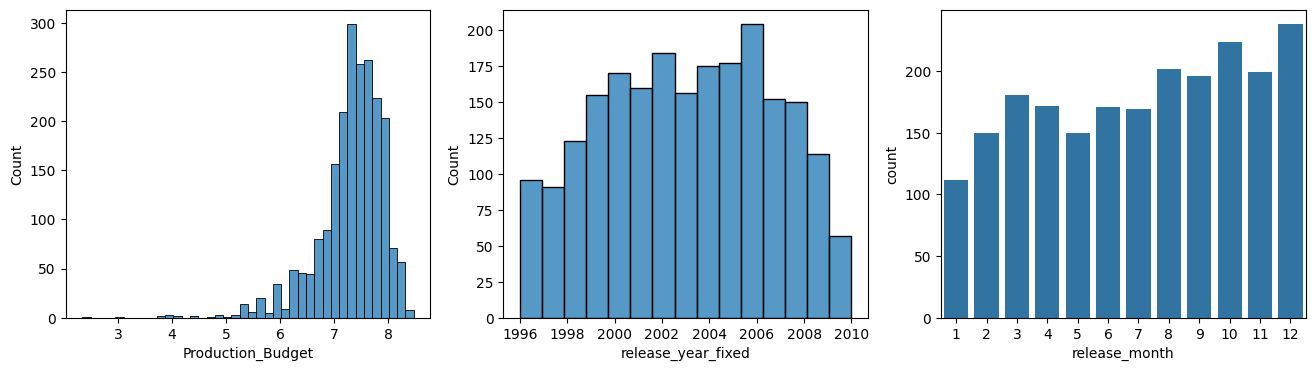

MPAA_Rating 6 {'G': 67, 'Not Rated': 50, 'NC-17': 5}
Major_Genre 12 {'Black Comedy': 28, 'Western': 15, 'Other': 5}
Source 9 {'Other': 54, 'Based on Play': 37, 'Based on Game': 18}
Creative_Type 8 {'Kids Fiction': 134, 'Factual': 41, 'Super Hero': 40}
Distributor 123 {'Black Diamond Pictures': 1, 'The Bigger Picture': 1, 'National Geographic Entertainment': 1}
                     mean  count
release_year_fixed              
1996                0.656     96
1997                0.692     91
1998                0.618    123
1999                0.568    155
2000                0.676    170
2001                0.681    160
2002                0.647    184
2003                0.686    156
2004                0.640    175
2005                0.695    177
2006                0.676    204
2007                0.625    152
2008                0.747    150
2009                0.746    114
2010                0.667     57
                mean  count
release_month              
1              0.607

In [120]:
# 1. Size and balance
print(len(model_df), model_df["success"].mean().round(3))

# 2. Distributions: do the earlier plots still look right?
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(np.log10(model_df["Production_Budget"]), bins=40, ax=ax[0])
sns.histplot(model_df["release_year_fixed"], bins=15, ax=ax[1])
sns.countplot(data=model_df, x="release_month", ax=ax[2])
plt.show()

# 3. Categorical levels after cleanup: which are still rare?
for c in ["MPAA_Rating", "Major_Genre", "Source", "Creative_Type", "Distributor"]:
    print(c, model_df[c].nunique(), model_df[c].value_counts().tail(3).to_dict())

# 4. Drift over time (decides how to cut the time-based split)
print(model_df.groupby("release_year_fixed")["success"].agg(["mean", "count"]).round(3))

# 5. Month pattern on the final rows
print(model_df.groupby("release_month")["success"].agg(["mean", "count"]).round(3))

# 6. Runtime gap on complete cases (confirms the sensitivity run is worth doing)
print(model_df.groupby(model_df["Running_Time_min"].isna())["success"].agg(["mean", "count"]).round(3))

We recheck the main findings on the final 2,164 films (1996+, complete metadata), since earlier tables were computed on other row sets.

- **Balance:** 66.7% successes.
- **Month:** success is 74.7% for summer (May-July), 70.3% for holidays (Nov-Dec) and 62.2% otherwise. September is weakest (55.1%). We keep release month, encoded as a 3-level season and compared with one-hot month.
- **Year:** success varies between 57% and 75% with no trend, but is higher in 2008-2010 (about 73%). A time-based test set will therefore have a higher base rate than the training set, so we report the baseline on the test set.
- **Runtime:** success is 79.9% when known vs. 50.9% when missing, so the gap survives complete cases. `Running_Time_min` stays out of the main model.
- **Categoricals:** a few levels are rare (`NC-17`, `Western`, `Based on Game`, and most of the 123 distributors), so the encoder groups infrequent levels using training data only.

# Time-based split on model_df

Because the goal is to predict films before release, we train on the past and test on the future. The cutoff is the 80% quantile of `Release_Date_fixed` (2007-04-22), fixed before any model was fit.

| Split | Period | Films | Success rate |
|---|---|---|---|
| Train | 1996 to Apr 2007 | 1,731 | 65.7% |
| Test | Apr 2007 to 2010 | 433 | 70.4% |

The test set has a higher base rate, so a model that always predicts "success" scores 70.4% accuracy there. We report balanced accuracy and ROC-AUC, which don't depend on the base rate, and compare every model against that baseline. `Release_Date_fixed` is used only to cut the split and is not a feature.

In [121]:
model_df = model_df.sort_values("Release_Date_fixed").reset_index(drop=True)
cut = model_df["Release_Date_fixed"].quantile(0.8)

train = model_df[model_df["Release_Date_fixed"] <= cut].copy()
test = model_df[model_df["Release_Date_fixed"] > cut].copy()

print(len(train), len(test))
print("cutoff:", cut.date())
print("train success:", train["success"].mean().round(3), "| test success:", test["success"].mean().round(3))

1731 433
cutoff: 2007-04-22
train success: 0.657 | test success: 0.704


# Baselines

Before building the full model, we fit two trivial models on the training set (1,731 films) and score them on the test set (433 films, Apr 2007 - 2010). They set the floor that any real model has to clear. Without them, a number like "70% accuracy" can't be interpreted.

- **Majority dummy:** ignores every feature and always predicts "success", the most common class in training. It answers: what does a model that learned nothing score?
- **Budget-only tree (depth 2, leaf 30):** a small tree that sees only `Production_Budget`. The label is `gross > budget`, so budget is the most obvious single signal. It answers: do the other features add anything beyond budget?

In [122]:
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score, roc_auc_score, f1_score

FEATURES_MAIN = ["Production_Budget", "release_month",
                 "MPAA_Rating", "Major_Genre", "Source", "Creative_Type", "Distributor"]

y_train, y_test = train["success"], test["success"]

def report(name, model, Xtr, Xte):
    model.fit(Xtr, y_train)
    pred = model.predict(Xte)
    proba = model.predict_proba(Xte)[:, 1]
    print(f"{name:22s} acc={accuracy_score(y_test, pred):.3f}  "
          f"bal_acc={balanced_accuracy_score(y_test, pred):.3f}  "
          f"auc={roc_auc_score(y_test, proba):.3f}  f1={f1_score(y_test, pred):.3f}")

report("majority dummy", DummyClassifier(strategy="most_frequent"),
       train[FEATURES_MAIN], test[FEATURES_MAIN])

report("budget-only tree (d=2)", DecisionTreeClassifier(max_depth=2, min_samples_leaf=30, random_state=42),
       train[["Production_Budget"]], test[["Production_Budget"]])

majority dummy         acc=0.704  bal_acc=0.500  auc=0.500  f1=0.827
budget-only tree (d=2) acc=0.704  bal_acc=0.500  auc=0.526  f1=0.827


We report AUC and balanced accuracy as the main metrics, because accuracy is misleading here: 70.4% of test films are successes, so predicting "success" for everything already scores 70.4%.

| Model | Accuracy | Balanced acc. | AUC | F1 |
|---|---|---|---|---|
| Majority dummy | 0.704 | 0.500 | 0.500 | 0.827 |
| Budget-only tree (depth 2) | 0.704 | 0.500 | 0.526 | 0.827 |

**Results**
- Both models predict "success" for every test film, so their accuracy, balanced accuracy and F1 are identical.
- Budget alone carries almost no ranking signal (AUC 0.526, within noise of chance), which matches the weak budget boxplot from the EDA.

**Bar for the full model:** clearly beat AUC of about 0.53 and balanced accuracy of 0.50. The baselines were fixed before any tuning, and the test set was not used to choose anything.


# Choosing the month encoding

Release month showed a seasonal pattern in the EDA (September weakest at 55%, summer and holidays strongest). A decision tree can use month in several ways, so before tuning we compare them using only the training set. The test set is not touched.

**Variants compared** (all use the same tree, depth 5 and leaf size 20, and the same categorical features):
- **Budget only:** a reference with no other features, to see whether anything beats budget alone.
- **Month numeric:** month as a number from 1 to 12. A tree can only split it into contiguous ranges.
- **Month one-hot:** one column per month, so the tree can isolate any set of months.
- **Season:** three groups from a fixed domain rule (summer May-July, holiday Nov-Dec, other), set before looking at these results.

**Setup**
- **Expanding-window validation:** for each year from 2002 to 2007, train on all earlier years and validate on that year. This respects time order, unlike random folds.
- `release_year_fixed` only defines the folds. The pipeline drops it, so the model never sees it.
- Categoricals are one-hot encoded, with rare levels grouped (fewer than 10 training rows for most columns, fewer than 20 for `Distributor`). The encoders are fit inside each fold, so nothing leaks from the validation year.

In [123]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import roc_auc_score, balanced_accuracy_score

# Fixed, domain-based season rule
def add_season(df):
    df = df.copy()
    df["release_season"] = df["release_month"].map(
        lambda m: "summer" if m in (5, 6, 7) else "holiday" if m in (11, 12) else "other")
    return df

train, test = add_season(train), add_season(test)

def make_model(cat_small, cat_dist, num_cols):
    parts = []
    if cat_small: parts.append(("cat", OneHotEncoder(min_frequency=10, handle_unknown="infrequent_if_exist"), cat_small))
    if cat_dist:  parts.append(("dist", OneHotEncoder(min_frequency=20, handle_unknown="infrequent_if_exist"), cat_dist))
    parts.append(("num", "passthrough", num_cols))
    return Pipeline([("prep", ColumnTransformer(parts)),
                     ("tree", DecisionTreeClassifier(max_depth=5, min_samples_leaf=20, random_state=42))])

def expanding_cv(model_fn, df, first_val_year=2002):
    rows = []
    for yr in range(first_val_year, 2008):
        tr, va = df[df["release_year_fixed"] < yr], df[df["release_year_fixed"] == yr]
        m = model_fn().fit(tr.drop(columns="success"), tr["success"])
        Xva = va.drop(columns="success")
        rows.append((yr, roc_auc_score(va["success"], m.predict_proba(Xva)[:, 1]),
                     balanced_accuracy_score(va["success"], m.predict(Xva))))
    return pd.DataFrame(rows, columns=["val_year", "auc", "bal_acc"])

base_cats = ["MPAA_Rating", "Major_Genre", "Source", "Creative_Type"]
variants = {
    "budget only": ([], [], ["Production_Budget"]),
    "month numeric": (base_cats, ["Distributor"], ["Production_Budget", "release_month"]),
    "month one-hot": (base_cats + ["release_month"],   ["Distributor"], ["Production_Budget"]),
    "season": (base_cats + ["release_season"],  ["Distributor"], ["Production_Budget"]),
}

for name, (cs, cd, cn) in variants.items():
    cols = cs + cd + cn + ["release_year_fixed", "success"]
    res = expanding_cv(lambda: make_model(cs, cd, cn), train[cols])
    print(f"{name:14s} auc={res['auc'].mean():.3f} (±{res['auc'].std():.3f})  bal_acc={res['bal_acc'].mean():.3f}")

budget only    auc=0.569 (±0.036)  bal_acc=0.498
month numeric  auc=0.554 (±0.015)  bal_acc=0.527
month one-hot  auc=0.564 (±0.016)  bal_acc=0.520
season         auc=0.572 (±0.045)  bal_acc=0.519


**Results** (mean over 6 validation years)

| Variant | AUC | +- across folds | Balanced acc. |
|---|---|---|---|
| Budget only | 0.569 | 0.036 | 0.498 |
| Month numeric | 0.554 | 0.015 | 0.527 |
| Month one-hot | 0.564 | 0.016 | 0.520 |
| Season | 0.572 | 0.045 | 0.519 |

- The four AUCs span 0.554 to 0.572, which is within fold-to-fold noise, so the encoding barely matters.
- The full models show a small edge over budget-only in balanced accuracy (0.52-0.527 vs. 0.498), but not in AUC.

**Decision:** We use `season`. It has the best mean AUC, the fewest columns, and a grouping fixed from domain knowledge before we saw the data. The choice is a tie broken by simplicity, not a clear win.

**Caveat:** each validation year has only about 100-200 films, so the AUC estimates are noisy. The depth and leaf size are placeholders here and are tuned in the next step.

# Tuning the tree (depth and leaf size)

The month encoding is settled (`season`), so we now tune the two settings that control how complex the tree can get: **maximum depth** and **minimum leaf size**. Signal in this data is weak, so a deep tree with many one-hot columns is likely to fit noise. We search small, simple settings on purpose. The test set is not touched.

**Grid:** depth in {2, 3, 4, 6} and minimum samples per leaf in {20, 40, 80}, 12 combinations in total.

**Setup**
- Same features as the chosen model: `MPAA_Rating`, `Major_Genre`, `Source`, `Creative_Type`, `release_season`, `Distributor` and `Production_Budget`.
- Same expanding-window validation as before (train on earlier years, validate on each year from 2002 to 2007). Encoders are fit inside each fold.
- Each setting is scored by mean AUC across the 6 folds, with the fold-to-fold standard deviation as a measure of stability.

In [124]:
import itertools

cs, cd, cn = base_cats + ["release_season"], ["Distributor"], ["Production_Budget"]
cols = cs + cd + cn + ["release_year_fixed", "success"]

def make_tuned(depth, leaf):
    parts = [("cat", OneHotEncoder(min_frequency=10, handle_unknown="infrequent_if_exist"), cs),
             ("dist", OneHotEncoder(min_frequency=20, handle_unknown="infrequent_if_exist"), cd),
             ("num", "passthrough", cn)]
    return Pipeline([("prep", ColumnTransformer(parts)),
                     ("tree", DecisionTreeClassifier(max_depth=depth, min_samples_leaf=leaf, random_state=42))])

rows = []
for depth, leaf in itertools.product([2, 3, 4, 6], [20, 40, 80]):
    res = expanding_cv(lambda: make_tuned(depth, leaf), train[cols])
    rows.append((depth, leaf, res["auc"].mean(), res["auc"].std(), res["bal_acc"].mean()))

grid = pd.DataFrame(rows, columns=["depth", "leaf", "auc", "auc_std", "bal_acc"]).round(3)
print(grid.sort_values("auc", ascending=False))

    depth  leaf    auc  auc_std  bal_acc
9       6    20  0.578    0.055    0.525
10      6    40  0.571    0.039    0.543
7       4    40  0.567    0.019    0.519
11      6    80  0.566    0.020    0.523
6       4    20  0.560    0.027    0.516
4       3    40  0.556    0.021    0.508
3       3    20  0.556    0.021    0.508
5       3    80  0.552    0.022    0.503
8       4    80  0.543    0.032    0.510
2       2    80  0.539    0.025    0.500
0       2    20  0.539    0.023    0.500
1       2    40  0.539    0.023    0.500


**Results** (top rows, sorted by AUC)

| Depth | Leaf | AUC | ± across folds | Balanced acc. |
|---|---|---|---|---|
| 6 | 20 | 0.578 | 0.055 | 0.525 |
| 6 | 40 | 0.571 | 0.039 | 0.543 |
| **4** | **40** | **0.567** | **0.019** | **0.519** |
| 6 | 80 | 0.566 | 0.020 | 0.523 |
| 4 | 20 | 0.560 | 0.027 | 0.516 |
| 3 | 20 / 40 | 0.556 | 0.021 | 0.508 |
| 2 | any | 0.539 | 0.023-0.025 | 0.500 |

- **Depth 2 gives identical results for every leaf size.** At that depth the tree only splits on budget, so it works as a budget-only floor (AUC 0.539).
- **Depth 3 predicts almost no flops** (balanced accuracy 0.503-0.508), so it behaves like the majority dummy.
- **The best AUC row is the least stable.** Depth 6 with leaf 20 has the highest AUC but also the largest spread (0.055), and it was the best of 12 tries, so its score is optimistic.
- **One-standard-error rule:** the standard error of the best row is about 0.055 / √6 ≈ 0.022, so every setting down to about 0.556 is statistically tied with it.

**Decision:** use **depth 4, leaf 40**. It is within one standard error of the best AUC, has the lowest spread in the table (0.019), and is simpler than depth 6. Depth 6 with leaf 40 (best balanced accuracy, 0.543, but twice the spread) is kept as a sensitivity run. The choice was made before looking at the test set.

**Caveat:** each validation year has only about 100-200 films, so differences of a few points in AUC are within noise. Tuning further on 1,731 training films would mostly fit the folds, so we stop here.

# Final evaluation on the test set

The model, features and settings are now fixed, so we score the chosen model once on the held-out test set (433 films, Apr 2007 - 2010) following these steps

- Fit the final model (depth 4, leaf 40, `season` encoding) on the training set only and scores the test set.
- Fit a **budget-only tree with the same depth and leaf size**, so the comparison with the full model is fair.
- Print the confusion matrix, per-class precision and recall, and the tree's top feature importances.

In [125]:
from sklearn.metrics import confusion_matrix, classification_report

final = make_tuned(4, 40).fit(train[cs + cd + cn], train["success"])
Xte = test[cs + cd + cn]
pred, proba = final.predict(Xte), final.predict_proba(Xte)[:, 1]

# Same-hyperparameter budget-only reference, for a fair comparison
bud = Pipeline([("t", DecisionTreeClassifier(max_depth=4, min_samples_leaf=40, random_state=42))]).fit(
    train[["Production_Budget"]], train["success"])
bp = bud.predict_proba(test[["Production_Budget"]])[:, 1]

print(f"full tree   acc={accuracy_score(y_test, pred):.3f} bal_acc={balanced_accuracy_score(y_test, pred):.3f} "
      f"auc={roc_auc_score(y_test, proba):.3f} f1={f1_score(y_test, pred):.3f}")
print(f"budget-only auc={roc_auc_score(y_test, bp):.3f}")
print(confusion_matrix(y_test, pred))
print(classification_report(y_test, pred, target_names=["flop", "success"], zero_division=0))

names = final["prep"].get_feature_names_out()
print(pd.Series(final["tree"].feature_importances_, index=names).sort_values(ascending=False).head(10).round(3))

full tree   acc=0.704 bal_acc=0.500 auc=0.632 f1=0.827
budget-only auc=0.533
[[  0 128]
 [  0 305]]
              precision    recall  f1-score   support

        flop       0.00      0.00      0.00       128
     success       0.70      1.00      0.83       305

    accuracy                           0.70       433
   macro avg       0.35      0.50      0.41       433
weighted avg       0.50      0.70      0.58       433

num__Production_Budget                     0.570
dist__Distributor_infrequent_sklearn       0.187
cat__release_season_summer                 0.116
cat__Creative_Type_Kids Fiction            0.078
cat__Creative_Type_Contemporary Fiction    0.049
cat__MPAA_Rating_Not Rated                 0.000
cat__MPAA_Rating_G                         0.000
cat__Major_Genre_Adventure                 0.000
cat__Major_Genre_Black Comedy              0.000
cat__Major_Genre_Comedy                    0.000
dtype: float64


**Results**

| Model | Accuracy | Balanced acc. | AUC |
|---|---|---|---|
| Majority dummy | 0.704 | 0.500 | 0.500 |
| Budget-only tree (depth 4, leaf 40) | - | - | 0.533 |
| Full tree (depth 4, leaf 40) | 0.704 | 0.500 | 0.632 |

- **The full tree ranks films better than budget alone** (AUC 0.632 vs. 0.533), so genre, creative type, distributor and season add information beyond budget.
- **At the default 0.5 threshold the tree predicts "success" for every film** (0 flops predicted), so accuracy, balanced accuracy and F1 equal the dummy's. No leaf has a success probability below 0.5. AUC is the metric that shows what the model learned.
- **Features used:** `Production_Budget` (0.570), small or independent distributors (0.187), summer release (0.116), Kids Fiction (0.078) and Contemporary Fiction (0.049). Summer and Kids Fiction match the EDA. Importances from a single tree are unstable, so they describe this tree and are not causal.

# Is the AUC gain over budget-only real? (paired bootstrap)

The full tree scored AUC 0.632 and the budget-only tree 0.533 on the test set. With only 433 films (128 flops), a gap of 0.10 could still be luck, so we check how much it varies under resampling.

**What the cell does**
- Draws 2,000 bootstrap resamples of the 433 test films, with replacement.
- On each resample it computes the full tree's AUC minus the budget-only tree's AUC, using the same films for both (a paired comparison).
- Reports the 2.5th, 50th and 97.5th percentiles of the gain.

**Result:** median gain **0.099**, 95% interval **0.037 to 0.160**.

- The interval excludes zero, so the extra features add ranking information beyond budget, and the gain is unlikely to be test-set noise.
- The range is wide, so the gain is probably positive but could be as small as 0.04.

In [126]:
rng = np.random.default_rng(42)
yt = y_test.to_numpy()
diffs = []
for _ in range(2000):
    idx = rng.integers(0, len(yt), len(yt))
    if yt[idx].min() == yt[idx].max():
        continue
    diffs.append(roc_auc_score(yt[idx], proba[idx]) - roc_auc_score(yt[idx], bp[idx]))
print(np.percentile(diffs, [2.5, 50, 97.5]).round(3))

[0.037 0.099 0.163]


# Hard predictions at a fixed threshold

At the default 0.5 threshold, the tree predicts "success" for every test film, so its accuracy, balanced accuracy and F1 equal the dummy's. The tree still ranks films sensibly (AUC 0.632), but no leaf has a success probability below 0.5. To see whether it can flag any flops, we move the threshold.

**Results** (threshold 0.657)

| | Predicted flop | Predicted success |
|---|---|---|
| Actual flop (128) | 92 | 36 |
| Actual success (305) | 179 | 126 |

- **Balanced accuracy 0.566** (up from 0.500). Flop recall is 72%, success recall is 41%.
- **Flop precision is 34%**, against a flop base rate of 30%, so a film flagged as a flop is only slightly more likely to be one.
- **Accuracy falls to 50%** (from 70%), because the model now flags 271 of 433 films as flops.
- **F1 falls to 0.540.** F1 here is for the success class, which the model now rejects more often.

**Interpretation:** the tree is useful for ranking films by risk, but its hard predictions are weak. Moving the threshold trades accuracy for flop detection, and whether that trade is worth it depends on the cost of missing a flop.

In [127]:
thr = train["success"].mean()
pred2 = (proba >= thr).astype(int)
print(f"thr={thr:.3f} bal_acc={balanced_accuracy_score(y_test, pred2):.3f} f1={f1_score(y_test, pred2):.3f}")
print(confusion_matrix(y_test, pred2))

thr=0.657 bal_acc=0.566 f1=0.540
[[ 92  36]
 [179 126]]


# **Conclusion**

**Research question.** Can a movie's commercial success (worldwide gross above production budget) be determined from information available before release?

**Answer.** Partly. Pre-release factors carry a modest, real signal: a decision tree ranks films better than budget alone (AUC 0.632 vs. 0.533, gain 0.099, 95% interval 0.037 to 0.160), using release season, distributor size and creative type. The signal is too weak to classify individual films reliably (balanced accuracy 0.566 at an adjusted threshold). This is plausible, because success depends heavily on factors outside the data (cast, marketing, competition, reviews), and the label itself is defined relative to budget. Strict leakage control and a time-based evaluation make the modest result trustworthy.

**Data decisions**
- Fixed century errors in `Release_Date` (22 classic films dated 100 years too late).
- Treated zero gross as missing and dropped rows without a usable label (55 of 3,201).
- Trained on 1996 onward, where film coverage triples and runtime reporting begins. Earlier films are survivorship-biased and priced in nominal dollars.
- Dropped `Running_Time_min` and all missing-value indicators. Missing runtime and missing metadata mark sparsely documented films that mostly flopped, and the gaps are unstable over time. A new film always has complete information.
- Kept complete cases for the categorical features (2,164 films, 66.7% successes) and merged rare categories.

**Modeling decisions**
- Time-based split: train on 1,731 films up to 2007-04-22, test on 433 films after it. Year is not a feature, because test years fall outside the training range.
- Release month encoded as a 3-level season (summer, holiday, other), chosen from a fixed domain rule. The encodings were statistically tied.
- Decision tree with depth 4 and minimum leaf size 40, chosen with expanding-window validation inside the training set.

**Results on the test set**

| Model | Accuracy | Balanced acc. | AUC |
|---|---|---|---|
| Majority dummy | 0.704 | 0.500 | 0.500 |
| Budget-only tree | - | - | 0.533 |
| Full tree | 0.704 | 0.500 (0.566 at threshold 0.657) | 0.632 |

- The full tree ranks films better than budget alone (AUC gain 0.099, 95% interval 0.037 to 0.160).
- It mainly used budget, small distributors, summer release and Kids Fiction.
- As a classifier it is weak. At the default threshold it predicts success for every film, and at the adjusted threshold accuracy falls to 50%.

**Limitations**
- One train/test cut with 433 test films, so AUC carries about ±0.05 of uncertainty. Cross-validation suggested a lower AUC (about 0.57).
- The data ends in 2010, and budgets and grosses are in nominal dollars.
- Results apply to films with complete metadata.